In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
try:
    from pytabkit import TabM_D_Classifier, RealMLP_TD_Classifier
except:
    !pip install -q pytabkit
    from pytabkit import TabM_D_Classifier, RealMLP_TD_Classifier

try:
    import xgboost as xgb
except:
    !pip install -q xgboost
    import xgboost as xgb

In [3]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep
from importlib.metadata import version

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, KBinsDiscretizer, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Set Configuration --
# sklearn.set_config(transform_output="pandas")
# pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 100)
sns.set_style("whitegrid")
# plt.style.use('ggplot')

print("xgboost  version:", xgb.__version__)
print("PyTabKit version:", version("pytabkit"))

xgboost  version: 3.4.1
PyTabKit version: 1.7.3


In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RED':    '\033[31m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig = pd.read_csv(PATH+"data.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items():
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

Train shape: (699635, 23)
Test shape: (299844, 22)
Orig shape: (129880, 22)

Frame type: <class 'pandas.core.frame.DataFrame'>


## FEATURE ENGINEERING

In [7]:
# ## -- Cyclic encoding --
# CYCLICS = []
# cy_cols = [c for c in train.columns if c.endswith("_hours")]

# for col in tqdm(cy_cols):
#     for p in [12, 24]:
#         n_s = f"{col}_sin_{p}"

#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         CYCLICS.append(n_s)

#         # n_c = f"{col}_cos_{p}"
#         # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         # CYCLICS.append(n_c)

# # NUMS.extend(CYCLICS)

# print(f"Cylcic Features created: {len(CYCLICS)}")
# print(train[CYCLICS].describe().T)

# train[CYCLICS].head()

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/CategoryMean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in tqdm(self.cols_to_encode, desc="TE encoding"):
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f"TE_{col}_{agg_func}"

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [9]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    pbar = tqdm(valid_features)
    for col in pbar:
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"
            pbar.set_description(f"Augmenting {col}")
            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

        pbar.set_description(f"Original augment complete!")

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                df[c] = df[c].fillna(global_mean)
            elif c.endswith('_median'):
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [10]:
# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total Features:", len(FEATURES))

# combined = pd.concat([train, test, orig])
# ## ------------------------------------------------------------
# # # -- Duplicate Nums as Cats --
# # CATS_2 = []
# # for c in tqdm(NUMS, title="nums_to_cats"):
# #     n = f"{c}_cat"
# #     combined[n] = combined[c].copy()
# #     CATS_2.append(n)
# # FEATURES.extend(CATS_2)
# ## ------------------------------------------------------------
# ## -- Factorize CATS --
# for c in tqdm(CATS, desc="factorize_cats"): # +INTER + new_cats
#     combined[c] = combined[c].factorize()[0]

# for c in tqdm(CATS, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")

# train = combined.iloc[:len(train)][FEATURES+[TARGET]]
# test  = combined.iloc[len(train):len(train)+len(test)][FEATURES]
# orig  = combined.iloc[len(train)+len(test):]

# del combined

In [11]:
ID = 'id'
TARGET = 'satisfaction'
train[TARGET] = train[TARGET].map({False: 0, True: 1})

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()
base_cols = cat_cols + num_cols

print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('Class', 'Type of Travel', 'Gender'),
    ('Class', 'Type of Travel', 'Age'),
    ('Flight Distance', 'Departure/Arrival time convenient'),
]
def feature_engineering(df, fit=False):
    # Fill NaNs
    for col in cat_cols:
        df[col] = df[col].fillna("missing")
    for col in num_cols:
        df[col] = df[col].fillna(0.0)
    
    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Count encoding
    for col in cat_cols + ['Leg room service']:
        count_name = f"_{col}_count"
        if fit:
            count_map = df[col].value_counts()
            category_map[count_name] = count_map
        else:
            count_map = category_map[count_name]
        df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category') 

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699635, 21)
X_test init shape: (299844, 21) 

init len(cat_cols): 4
init len(num_cols): 17 

len(new_cat_cols): 20
len(new_num_cols): 5 

prep len(cat_cols): 24
prep len(num_cols): 22 

X      prep shape: (699635, 46)
X_test prep shape: (299844, 46) 



In [12]:
X.dtypes

Age                                                      int64
Flight Distance                                          int64
Inflight wifi service                                    int64
Departure/Arrival time convenient                        int64
Ease of Online booking                                   int64
Gate location                                            int64
Food and drink                                           int64
Online boarding                                          int64
Seat comfort                                             int64
Inflight entertainment                                   int64
On-board service                                         int64
Leg room service                                         int64
Baggage handling                                         int64
Checkin service                                          int64
Cleanliness                                              int64
Departure Delay in Minutes                             

In [13]:
X.nunique()

Age                                                      75
Flight Distance                                        3474
Inflight wifi service                                     6
Departure/Arrival time convenient                         6
Ease of Online booking                                    6
Gate location                                             6
Food and drink                                            6
Online boarding                                           6
Seat comfort                                              6
Inflight entertainment                                    6
On-board service                                          6
Leg room service                                          6
Baggage handling                                          5
Checkin service                                           6
Cleanliness                                               6
Departure Delay in Minutes                              167
Arrival Delay in Minutes                

# ML TRAINING

In [14]:
X.columns == X_test.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

In [15]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

USE_FULL_TRAIN = False
x_sample, x_sample2 = train_test_split(
    pd.concat([X, y], axis=1),
    train_size=100_000,
    stratify=y,
    random_state=42,
)

train_X = pd.concat([X, y], axis=1).copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))
train_X.head()

(100000, 47) <class 'pandas.core.frame.DataFrame'>


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Age_cat_,Flight Distance_cat_,Inflight wifi service_cat_,Departure/Arrival time convenient_cat_,Ease of Online booking_cat_,Gate location_cat_,Food and drink_cat_,Online boarding_cat_,Seat comfort_cat_,Inflight entertainment_cat_,On-board service_cat_,Leg room service_cat_,Baggage handling_cat_,Checkin service_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,Arrival Delay in Minutes_cat_,_Gender_count,_Customer Type_count,_Type of Travel_count,_Class_count,_Leg room service_count,Class_Type of Travel_Gender_,Class_Type of Travel_Age_,Flight Distance_Departure/Arrival time convenient_,satisfaction
0,34,328,3,0,3,5,5,3,5,5,3,4,4,5,5,6,0.0,Male,Loyal Customer,Personal Travel,Eco,5,256,2,4,3,1,1,1,3,1,0,0,0,2,2,5,0,351683,576990,202194,327404,204124,2,163,949,0
1,40,2845,5,5,5,5,5,4,4,4,4,4,4,4,3,4,1.0,Male,Loyal Customer,Business travel,Business,39,880,1,1,1,1,1,0,1,3,2,0,0,1,1,10,16,351683,576990,497441,342212,204124,1,61,3784,1
2,53,228,4,4,4,4,1,3,4,4,4,4,4,5,4,0,0.0,Female,Loyal Customer,Business travel,Business,35,1001,0,0,0,2,0,1,1,3,2,0,0,2,4,0,0,347952,576990,497441,342212,204124,4,85,3712,1
3,48,539,5,5,5,5,5,4,5,4,4,4,4,3,3,0,0.0,Male,Loyal Customer,Business travel,Business,13,1273,1,1,1,1,1,0,3,3,2,0,0,0,1,0,0,351683,576990,497441,342212,204124,1,14,3830,1
4,41,1892,5,1,5,3,4,5,4,4,2,1,4,4,4,0,0.0,Male,Loyal Customer,Personal Travel,Eco,15,659,1,5,1,0,3,4,1,3,3,4,0,1,4,0,0,351683,576990,202194,327404,53094,2,16,1482,1


In [16]:
_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print("Total Features:", len(FEATURES))

# train_X.head()

Total Features: 46


In [17]:
# Handle optional original table aggregations securely if flags enable them
USE_ORIGINAL = True

if USE_ORIGINAL and "original_TE" in globals():
    feats_update = FEATURES.copy()
    aggs_ = ["mean"]
    X_tr, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, X_test, target=TARGET, features=base_cols, aggs=aggs_, fill_nan=True
    )
    feats_update.extend(orig_cols)
    X_1 = X_tr[feats_update].copy()
    y_1 = X_tr[TARGET].astype("int32")
    X_tst = x_test[feats_update].copy()
else:
    X_1 = train_X[FEATURES].copy()
    y_1 = train_X[TARGET].astype("int32")
    X_tst = X_test[FEATURES].copy()

print(X_1.shape, type(X_1))
X_1.head(3)

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

(100000, 67) <class 'pandas.core.frame.DataFrame'>


,Gate location,Flight Distance_cat_,Cleanliness_cat_,Departure Delay in Minutes_cat_,_Customer Type_count,Departure Delay in Minutes,Seat comfort_cat_,_Gender_count,Class,Gender,Checkin service,Inflight entertainment_cat_,Leg room service_cat_,Arrival Delay in Minutes_cat_,Gate location_cat_,On-board service_cat_,Flight Distance,Age,Checkin service_cat_,Flight Distance_Departure/Arrival time convenient_,_Type of Travel_count,Type of Travel,Baggage handling,On-board service,Cleanliness,_Class_count,Class_Type of Travel_Gender_,Online boarding_cat_,_Leg room service_count,Departure/Arrival time convenient,Customer Type,Food and drink_cat_,Inflight entertainment,Baggage handling_cat_,Ease of Online booking_cat_,Food and drink,Leg room service,Class_Type of Travel_Age_,Inflight wifi service_cat_,Inflight wifi service,Arrival Delay in Minutes,Seat comfort,Online boarding,Departure/Arrival time convenient_cat_,Ease of Online booking,Age_cat_,oTE_Gender_mean,oTE_Customer Type_mean,oTE_Type of Travel_mean,oTE_Class_mean,oTE_Age_mean,oTE_Flight Distance_mean,oTE_Inflight wifi service_mean,oTE_Departure/Arrival time convenient_mean,oTE_Ease of Online booking_mean,oTE_Gate location_mean,oTE_Food and drink_mean,oTE_Online boarding_mean,oTE_Seat comfort_mean,oTE_Inflight entertainment_mean,oTE_On-board service_mean,oTE_Leg room service_mean,oTE_Baggage handling_mean,oTE_Checkin service_mean,oTE_Cleanliness_mean,oTE_Departure Delay in Minutes_mean,oTE_Arrival Delay in Minutes_mean
0,5,256,2,5,576990,6,3,351683,Eco,Male,5,1,0,0,1,0,328,34,2,949,202194,Personal Travel,4,3,5,327404,2,1,204124,0,Loyal Customer,1,5,0,3,5,4,163,2,3,0.0,5,3,4,3,5,0.440115,0.478115,0.101326,0.187673,0.377161,0.303109,0.251825,0.481066,0.310104,0.568040,0.550882,0.137626,0.651336,0.650615,0.318093,0.583096,0.480636,0.611714,0.612472,0.427813,0.474070
1,5,880,1,10,576990,4,1,351683,Business,Male,4,3,0,16,1,2,2845,40,1,3784,497441,Business travel,4,4,3,342212,1,0,204124,5,Loyal Customer,1,4,0,1,5,4,61,1,5,1.0,4,4,1,5,39,0.440115,0.478115,0.583724,0.694434,0.571206,0.439024,0.990178,0.424709,0.734676,0.568040,0.550882,0.623011,0.560293,0.611128,0.534584,0.583096,0.480636,0.460023,0.433075,0.436553,0.483801
2,4,1001,4,0,576990,0,1,347952,Business,Female,5,3,0,0,2,2,228,53,2,3712,497441,Business travel,4,4,4,342212,4,1,204124,4,Loyal Customer,0,4,0,0,1,4,85,0,4,0.0,4,3,0,4,35,0.428975,0.478115,0.583724,0.694434,0.588978,0.333333,0.600767,0.388614,0.531623,0.390698,0.199551,0.137626,0.560293,0.611128,0.534584,0.583096,0.480636,0.611714,0.535282,0.459390,0.474070


In [18]:
real_params = {
    'random_state': 42,
    'verbosity': 2,
    'val_metric_name': '1-auc_ovr',

    'n_ens': 8,
    'n_epochs': 3,
    'batch_size': 256,
    'use_early_stopping': False,
    'early_stopping_additive_patience': 10,
    'early_stopping_multiplicative_patience': 1,

    'lr': 0.053,
    'wd': 0.015,
    'sq_mom': 0.988,
    'lr_sched': 'flat_anneal',
    'wd_sched': 'cos_log_15',
    'first_layer_lr_factor': 0.25,

    'embedding_size': 5,
    'max_one_hot_cat_size': 1,
    'hidden_sizes': [512, 256, 128],
    'act': 'silu',
    'p_drop': 0.05,
    'p_drop_sched': 'pow5',

    'plr_hidden_1': 16,
    'plr_hidden_2': 8,
    'plr_act_name': 'gelu',
    'plr_lr_factor': 0.1151,
    'plr_sigma': 2.33,

    'ls_eps': 0.01,
    'ls_eps_sched': 'sqrt_cos',

    'add_front_scale': False,
    'bias_init_mode': 'neg-uniform-dynamic-2',
    'tfms': ['one_hot', 'median_center', 'robust_scale',
             'smooth_clip', 'embedding', 'l2_normalize'],
}

real_params

{'random_state': 42,
 'verbosity': 2,
 'val_metric_name': '1-auc_ovr',
 'n_ens': 8,
 'n_epochs': 3,
 'batch_size': 256,
 'use_early_stopping': False,
 'early_stopping_additive_patience': 10,
 'early_stopping_multiplicative_patience': 1,
 'lr': 0.053,
 'wd': 0.015,
 'sq_mom': 0.988,
 'lr_sched': 'flat_anneal',
 'wd_sched': 'cos_log_15',
 'first_layer_lr_factor': 0.25,
 'embedding_size': 5,
 'max_one_hot_cat_size': 1,
 'hidden_sizes': [512, 256, 128],
 'act': 'silu',
 'p_drop': 0.05,
 'p_drop_sched': 'pow5',
 'plr_hidden_1': 16,
 'plr_hidden_2': 8,
 'plr_act_name': 'gelu',
 'plr_lr_factor': 0.1151,
 'plr_sigma': 2.33,
 'ls_eps': 0.01,
 'ls_eps_sched': 'sqrt_cos',
 'add_front_scale': False,
 'bias_init_mode': 'neg-uniform-dynamic-2',
 'tfms': ['one_hot',
  'median_center',
  'robust_scale',
  'smooth_clip',
  'embedding',
  'l2_normalize']}

In [19]:
core_params = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "enable_categorical": True,
    "verbosity": 0,
    "tree_method": 'hist',
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

gbt_params = core_params | {}
los_params = core_params | {'grow_policy': "lossguide"}
gra_params = core_params | {'sampling_method': "gradient_based"}

xgb_params = {
    'gbt': ("XGBgbt", gbt_params),
    'los': ("XGBlos", los_params),
    'gra': ("XGBgra", gra_params),
}

xgb_params

{'gbt': ('XGBgbt',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cpu'}),
 'los': ('XGBlos',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cpu',
   'grow_policy': 'lossguide'}),
 'gra': ('XGBgra',
  {'objective': 'binary:logistic',
   'eval_metric': 'auc',
   'enable_categorical': True,
   'verbosity': 0,
   'tree_method': 'hist',
   'device': 'cpu',
   'sampling_method': 'gradient_based'})}

In [20]:
## -- Pseudo Trainer --
m1_name = "RealMLP"
m_id = 'gbt'  # "gbt", "los", "gra"
m2_name = xgb_params[m_id][0]

USE_TE  = True
DROP_TE = True

oof_preds  = np.zeros(len(X_1))
test_preds = np.zeros(len(X_tst))

fold_scores = []
m1_scores   = []
feat_importances = []

t0 = time()

## -- Initiate Training --
for idx, (train_idx, val_idx) in enumerate(skf.split(X_1, y_1), 1):
    print(f"\n{'#'*30}")
    print(f"+++ FOLD {idx}/{skf.n_splits} | ⚡️ {m2_name}-{m1_name}")
    print(f"{'#'*30}")

    X_train, X_valid = X_1.iloc[train_idx], X_1.iloc[val_idx]
    y_train, y_valid = y_1.iloc[train_idx], y_1.iloc[val_idx]
    X_test_fold = X_tst.copy()

    # ## -- OPTION A: Concatenate original data --
    # X_train = pd.concat([X_train, orig[FEATURES]], ignore_index=True)
    # y_train = pd.concat([y_train, orig[TARGET]], ignore_index=True)
    # y_train = np.concatenate([y_train, orig[TARGET].values], axis=0)

    if USE_TE:
        te_cols = combo_names
        # custom TE
        # print(f" ⧗ custom TE ({len(te_cols)}) features", end=" | ")
        # te_enc  = customTE(te_cols, cv=5, smooth='auto', aggs=['mean'], drop_original=DROP_TE)
        # X_train = te_enc.fit_transform(X_train, y_train)
        # X_valid = te_enc.transform(X_valid)
        # X_test_fold = te_enc.transform(X_test_fold)

        # sklearn TE
        print(f" ⧗ sklearn TE ({len(te_cols)}) features")
        te_enc = skTE(target_type='binary', cv=5, smooth='auto', random_state=42)
        tr_enc = te_enc.fit_transform(X_train[te_cols], y_train)
        va_enc = te_enc.transform(X_valid[te_cols])
        ts_enc = te_enc.transform(X_test_fold[te_cols])

        te_names = [f"TE_{col}_" for col in te_cols]
        X_train[te_names]  = tr_enc
        X_valid[te_names] = va_enc
        X_test_fold[te_names] = ts_enc

        combos_to_drop = [
            'Class_Type of Travel_Age_',
            'Flight Distance_Departure/Arrival time convenient_',
        ]
        X_train = X_train.drop(columns=combos_to_drop)
        X_valid = X_valid.drop(columns=combos_to_drop)
        X_test_fold = X_test_fold.drop(columns=combos_to_drop)

    # # ---- Imputing ----
    # # imputer = IterativeImputer(max_iter=20, tol=1e-3, random_state=0) # n_nearest_features=10, 
    # imputer = SimpleImputer(strategy="median")
    # X_train[all_nums] = imputer.fit_transform(X_train[all_nums], y_train)
    # X_valid[all_nums] = imputer.transform(X_valid[all_nums])
    # X_test[all_nums]  = imputer.transform(X_test[all_nums])

    # cme_encoder = CategoryMeanTransformer(cat_cols=new_cats)
    # X_train = cme_encoder.fit_transform(X_train, y_train)
    # X_valid = cme_encoder.transform(X_valid)
    # X_test  = cme_encoder.transform(X_test)

    all_cats = [c for c in cat_cols if c not in combos_to_drop]

    ## -- Select base model --
    model_1 = RealMLP_TD_Classifier(**real_params)

    model_1.fit(X_train, y_train, X_valid, y_valid) #, cat_col_names=all_cats
    oof_m1  = model_1.predict_proba(X_valid)[:, 1]
    test_m1 = model_1.predict_proba(X_test_fold)[:, 1]

    score_m1 = roc_auc_score(y_valid, oof_m1)
    print(f"{CFG['YELLOW']} • {m1_name} AUC: {score_m1:.6f}{CFG['RESET']}")
    m1_scores.append(score_m1)
        
    print(f"train= {X_train.shape}, valid= {X_valid.shape}")
    if idx == 1: display(X_train.head(3))

    ## -- Pseudo labels from model_1 as features for model_2 --
    X_train_full = pd.concat([X_train, X_valid, X_test_fold])
    y_train_full = np.concatenate([y_train.to_numpy(), oof_m1, test_m1], axis=0)

    for c in cat_cols[:4]:
        X_train_full[c] = X_train_full[c].astype('category')

    X_valid_2 = X_train_full.iloc[len(X_train):len(X_train)+len(X_valid)]
    X_test_2  = X_train_full.iloc[len(X_train)+len(X_valid):]

    dtrain = xgb.DMatrix(X_train_full, y_train_full, enable_categorical=True)
    dval   = xgb.DMatrix(X_valid_2, y_valid, enable_categorical=True)
    dtest  = xgb.DMatrix(X_test_2, enable_categorical=True)

    # -------------------------------------------------------------------------
    if m_id == 'gbt':
        use_params = {
            # GBDT ---
            'max_depth': 8,
            'subsample': 0.871,
            'colsample_bytree': 0.371,
            'min_child_weight': 19,
            'reg_alpha': 0.0018013055409110675,
            'reg_lambda': 7.891187596933341e-07,
            'gamma': 1.2606877093584014e-08,
        }
    elif m_id == 'los':
        use_params = {
            # LOSS ---
            'max_depth': 0,
            'max_leaves': 126, # increase in optuna ⚠️
            'subsample': 0.637,
            'colsample_bytree': 0.919,
            'min_child_weight': 47, # increase in optuna ⚠️
            'reg_alpha': 0.00032132892047415746,
            'reg_lambda': 2.572993871356861e-08,
            'gamma': 0.0010303560661436676,
        }
    else:
        use_params = {
            # GRADIENT ---
            'max_depth': 10, # increase in optuna ⚠️
            'subsample': 0.589,
            'colsample_bytree': 0.597,
            'min_child_weight': 23,
            'reg_alpha': 1.1166077787987638e-05,
            'reg_lambda': 0.00011563663871479361,
            'gamma': 2.5305201567863063e-07,
        }

    seeder = 42 # + (idx-1)
    m2_params = xgb_params[m_id][1].copy()
    m2_params.update(
        {
            'learning_rate': 0.01,
            'random_state': seeder
        } | use_params
    )
    # -------------------------------------------------------------------------
    model_2 = xgb.train(
        m2_params,
        dtrain,
        num_boost_round=10_000,
        evals=[(dtrain, "train"), (dval, "valid")],
        early_stopping_rounds=100,
        verbose_eval=1000,
    )
    imp_dict = model_2.get_score(importance_type='gain')
    imp_values = [imp_dict.get(feat, 0.0) for feat in X_train_full.columns]
    feat_importances.append(np.asarray(imp_values))
    val_preds = model_2.predict(dval, iteration_range=(0, model_2.best_iteration+1))
    fold_test_preds = model_2.predict(dtest, iteration_range=(0, model_2.best_iteration+1))
    # -------------------------------------------------------------------------
    # model_2 = xgb.XGBClassifier(**m2_params)
    # model_2.fit(
    #     X_train_full, y_train_full, verbose=500,
    #     eval_set = [(X_valid_2, y_valid)], # (X_train_full, y_train_full), 
    #     # base_margin = trn_margin,
    #     # base_margin_eval_set=[trn_margin, val_margin],
    # )
    # feat_importances.append(np.asarray(model_2.feature_importances_))
    # val_preds = model_2.predict_proba(X_valid_2)[:, 1]
    # fold_test_preds = model.predict_proba(X_test_2)[:, 1]
    # -------------------------------------------------------------------------

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds / FOLDS

    score_m2 = roc_auc_score(y_valid, val_preds)
    fold_scores.append(score_m2)

    print(f"{CFG['YELLOW']} • {m2_name} AUC: {score_m2:.6f}{CFG['RESET']}")

    if score_m2 >= score_m1:
        print(f"{CFG['GREEN']} • 🍀 improved: {score_m2-score_m1:.6f}{CFG['RESET']}")
    else:
        print(f"{CFG['RED']} • ⚠️ declined: {score_m1-score_m2:.6f}{CFG['RESET']}")

    # gc.collect()
    torch.cuda.empty_cache()

model_name = f"{m2_name}-{m1_name}" + f"({X_train_full.shape[1]})"
features_used = X_train_full.columns

print('\n'+'='*50)
print(f"{FOLDS}-FOLD CV: {model_name} | shape: {X_train_full.shape}")
print('='*50)

## -- CV results --
m1_fold_results = {}
m2_fold_results = {}
for i, (s1, s2) in enumerate(zip(m1_scores, fold_scores), 1):  
    print(f" • Fold {i} AUC: {m1_name}={s1:.6f} | {m2_name}={s2:.6f}")
    m1_fold_results[f"fold_{i}"] = s1
    m2_fold_results[f"fold_{i}"] = s2

oof_auc = np.round(roc_auc_score(y_1, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

m1avg_auc = np.round(np.mean(m1_scores), 6)
m1std_auc = np.round(np.std(m1_scores), 6)

print(f"{'-'*50}")
print(f"AVG AUC({m1_name}): {m1avg_auc} ± {m1std_auc}")
print(f"AVG AUC({m2_name}) : {avg_auc:} ± {std_auc}")
print(f"OOF AUC({m2_name}) : {oof_auc:}")
print(f"{'-'*50}")

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins")

del X_train_full, y_train_full, X_train, X_valid, y_train, y_valid, X_valid_2, X_test_2
del dtrain, dval, dtest, model_1, model_2


##############################
+++ FOLD 1/5 | ⚡️ XGBgbt-RealMLP
##############################
 ⧗ sklearn TE (3) features
Columns classified as continuous: ['Gate location', '_Customer Type_count', 'Departure Delay in Minutes', '_Gender_count', 'Checkin service', 'Flight Distance', 'Age', '_Type of Travel_count', 'Baggage handling', 'On-board service', 'Cleanliness', '_Class_count', '_Leg room service_count', 'Departure/Arrival time convenient', 'Inflight entertainment', 'Food and drink', 'Leg room service', 'Inflight wifi service', 'Arrival Delay in Minutes', 'Seat comfort', 'Online boarding', 'Ease of Online booking', 'oTE_Gender_mean', 'oTE_Customer Type_mean', 'oTE_Type of Travel_mean', 'oTE_Class_mean', 'oTE_Age_mean', 'oTE_Flight Distance_mean', 'oTE_Inflight wifi service_mean', 'oTE_Departure/Arrival time convenient_mean', 'oTE_Ease of Online booking_mean', 'oTE_Gate location_mean', 'oTE_Food and drink_mean', 'oTE_Online boarding_mean', 'oTE_Seat comfort_mean', 'oTE_Inflight en

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Epoch 1/3: val 1-auc_ovr = 0.043566
Epoch 2/3: val 1-auc_ovr = 0.042809
Epoch 3/3: val 1-auc_ovr = 0.042866


`Trainer.fit` stopped: `max_epochs=3` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


 • RealMLP AUC: 0.957191
train= (80000, 68), valid= (20000, 68)


...

 • RealMLP AUC: 0.959240
train= (80000, 68), valid= (20000, 68)
[0]	train-auc:0.94600	valid-auc:0.94906
[1000]	train-auc:0.95738	valid-auc:0.95896
[2000]	train-auc:0.95870	valid-auc:0.95920
[2335]	train-auc:0.95902	valid-auc:0.95923
 • XGBgbt AUC: 0.959236
 • ⚠️ declined: 0.000004

##############################
+++ FOLD 5/5 | ⚡️ XGBgbt-RealMLP
##############################
 ⧗ sklearn TE (3) features
Columns classified as continuous: ['Gate location', '_Customer Type_count', 'Departure Delay in Minutes', '_Gender_count', 'Checkin service', 'Flight Distance', 'Age', '_Type of Travel_count', 'Baggage handling', 'On-board service', 'Cleanliness', '_Class_count', '_Leg room service_count', 'Departure/Arrival time convenient', 'Inflight entertainment', 'Food and drink', 'Leg room service', 'Inflight wifi service', 'Arrival Delay in Minutes', 'Seat comfort', 'Online boarding', 'Ease of Online booking', 'oTE_Gender_mean', 'oTE_Customer Type_mean', 'oTE_Type of Travel_mean', 'oTE_Class_mean',

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Epoch 1/3: val 1-auc_ovr = 0.043114
Epoch 2/3: val 1-auc_ovr = 0.042151
Epoch 3/3: val 1-auc_ovr = 0.042511


`Trainer.fit` stopped: `max_epochs=3` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


 • RealMLP AUC: 0.957849
train= (80000, 68), valid= (20000, 68)
[0]	train-auc:0.94336	valid-auc:0.94924
[1000]	train-auc:0.95482	valid-auc:0.95804
[1431]	train-auc:0.95553	valid-auc:0.95814
 • XGBgbt AUC: 0.958156
 • 🍀 improved: 0.000307

5-FOLD CV: XGBgbt-RealMLP(68) | shape: (399844, 68)
 • Fold 1 AUC: RealMLP=0.957191 | XGBgbt=0.957690
 • Fold 2 AUC: RealMLP=0.957316 | XGBgbt=0.958482
 • Fold 3 AUC: RealMLP=0.960388 | XGBgbt=0.960082
 • Fold 4 AUC: RealMLP=0.959240 | XGBgbt=0.959236
 • Fold 5 AUC: RealMLP=0.957849 | XGBgbt=0.958156
--------------------------------------------------
AVG AUC(RealMLP): 0.958397 ± 0.001233
AVG AUC(XGBgbt) : 0.958729 ± 0.000843
OOF AUC(XGBgbt) : 0.958619
--------------------------------------------------
29.97 mins


In [21]:
# ==================================================
# 5-FOLD CV: XGBgbt-RealMLP(68) | shape: (399844, 68)
# ==================================================
#  • Fold 1 AUC: RealMLP=0.957244 | XGBgbt=0.957823
#  • Fold 2 AUC: RealMLP=0.957605 | XGBgbt=0.958079
#  • Fold 3 AUC: RealMLP=0.959926 | XGBgbt=0.960408
#  • Fold 4 AUC: RealMLP=0.959560 | XGBgbt=0.959369
#  • Fold 5 AUC: RealMLP=0.957821 | XGBgbt=0.958318
# --------------------------------------------------
# AVG AUC(RealMLP)  : 0.958431 ± 0.001093
# AVG AUC(XGBgbt): 0.9588 ± 0.000961
# OOF AUC(XGBgbt): 0.958734
# --------------------------------------------------
# 32.46 mins

# ==================================================
# 5-FOLD CV: XGBgbt/RealMLP(47) | shape: (399844, 47)
# ==================================================
#  • Fold 1 AUC: RealMLP=0.956977 | XGBgbt=0.957374
#  • Fold 2 AUC: RealMLP=0.957260 | XGBgbt=0.957981
#  • Fold 3 AUC: RealMLP=0.959684 | XGBgbt=0.959443
#  • Fold 4 AUC: RealMLP=0.959578 | XGBgbt=0.959142
#  • Fold 5 AUC: RealMLP=0.957936 | XGBgbt=0.958279
# --------------------------------------------------
# AVG AUC(RealMLP)  : 0.958287 ± 0.001141
# AVG AUC(XGBgbt): 0.958444 ± 0.000758
# OOF AUC(XGBgbt): 0.958316
# --------------------------------------------------
# 28.77 mins

In [22]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

m1_df = pd.DataFrame.from_dict(m1_fold_results, orient='index', columns=['tabm_auc'])
m2_df = pd.DataFrame.from_dict(m2_fold_results, orient='index', columns=['pseudo_auc'])
print(pd.concat([m1_df, m2_df], axis=1).to_string())

print(f"{'-'*40}")
print(f"AVG AUC({m1_name})  : {m1avg_auc} ± {m1std_auc}")
print(f"AVG AUC({n}): {avg_auc:} ± {std_auc}")
print(f"{'-'*40}")

print(f"{tt:.2f} mins")

        tabm_auc  pseudo_auc
fold_1  0.957191    0.957690
fold_2  0.957316    0.958482
fold_3  0.960388    0.960082
fold_4  0.959240    0.959236
fold_5  0.957849    0.958156
----------------------------------------
AVG AUC(RealMLP)  : 0.958397 ± 0.001233
AVG AUC(XGBgbt-RealMLP(68)_958729): 0.958729 ± 0.000843
----------------------------------------
29.97 mins


## SUBMISSION

In [23]:
## -- Save submission file --
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.237039
1,699636,0.928336
2,699637,0.909861
3,699638,0.051154
4,699639,0.041915
...,...,...
299839,999474,0.059451
299840,999475,0.030930
299841,999476,0.254371
299842,999477,0.023801


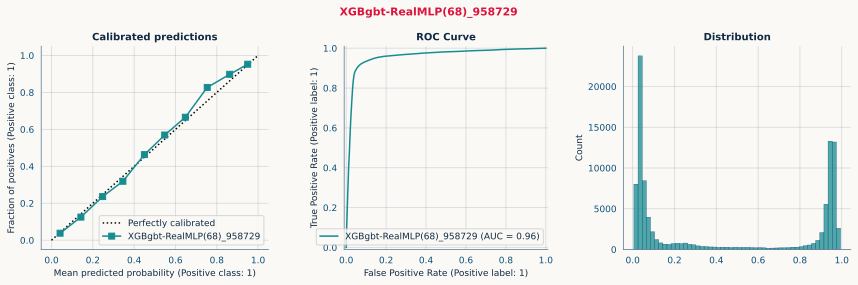

In [24]:
## -- Plot predictions errors --
_, axs = plt.subplots(1, 3, figsize=(12, 4))

CalibrationDisplay.from_predictions(y_1, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title("Calibrated predictions")

RocCurveDisplay.from_predictions(y_1, oof_preds, name=n, ax=axs[1])
axs[1].set_title("ROC Curve")
# axs[1].grid(False)

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title("Distribution")

plt.suptitle(n, weight='bold', color=CRIM)
plt.tight_layout()
plt.show()

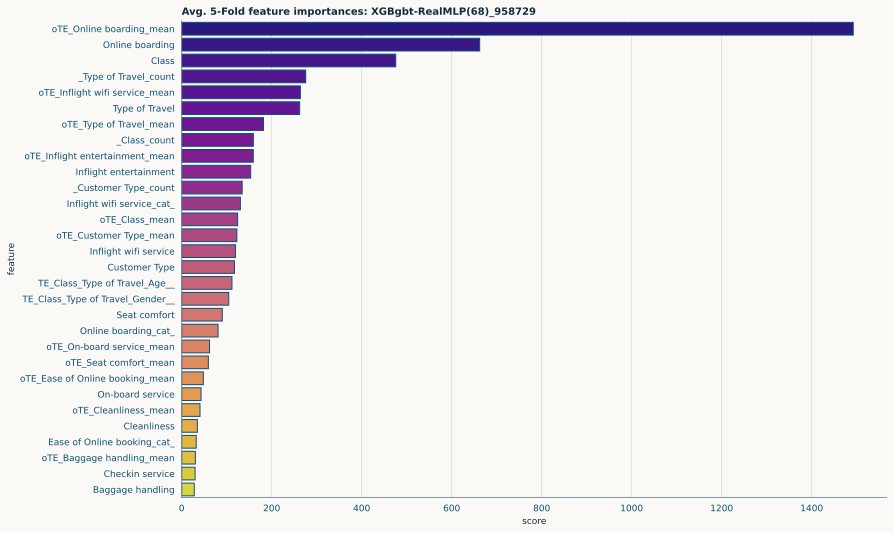

In [25]:
## -- Get feature importances --
top_n = 30
    
fi_df = pd.DataFrame(
    {
        "feature": features_used,
        "score": np.mean(feat_importances, axis=0),
    }
).sort_values(by="score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(12.5, top_n*0.25))
sns.barplot(data=fi_df.head(top_n), x="score", y="feature", palette='plasma')
plt.title(f"Avg. {FOLDS}-Fold feature importances: {n}", loc='left')

plt.tight_layout()
plt.show()

print()

In [26]:
# !rm -r /kaggle/working